# 11 – Entdecker-Modus (Etappe 9, Stufe 3)

**Was:** Zufällig einen geeigneten öffentlichen NIRCam-Datensatz in MAST finden, automatisch eine Konfiguration mit Standardwerten schreiben und die Pipeline laufen lassen.

**Regeln** (`astropipe.explore`):
- NIRCam-Bildgebung, Stufe 3, öffentlich, wissenschaftliche Aufnahme (keine Kalibrierung)
- kein Ziel im Sonnensystem (bewegt sich), gültige Koordinaten
- eine Beobachtung (gleiche Ausrichtung) mit ≥ 3 Filtern, genau eine i2d-Datei pro Filter, ≤ 3 GB
- zufälliges 30-Tage-Fenster zwischen Juli 2022 und ≈ 13 Monaten vor heute

**Standardwerte:** keine Streifenkorrektur, asinh (a = 0,05, k = 0,5, 99,9 %), Farbe A (chromatisch), quadratischer Ausschnitt. Das Ergebnis ist eine **Vorschau** – gefällt ein Kandidat, wird die erzeugte TOML in `configs/explore/` von Hand verfeinert.

**Im Terminal:** `python -m astropipe.explore` (mit `--seed 42` reproduzierbar, `--no-run` nur suchen).

## Ergebnis

`python -m astropipe.explore` durchsucht MAST in einem zufälligen 30-Tage-Fenster nach öffentlicher NIRCam-Bildgebung (Stufe 3, ≥ 3 Filter, ≤ 3 GB), schreibt eine Standard-Konfiguration (`configs/explore/`), lässt die Pipeline laufen und erstellt einen Kurzbericht mit Warnhinweisen (`output/runs/<prefix>_report.md`).

Erster Fund: `jw08277-o004_t003`, Feld bei NGC 1527 (Programm 8277), F115W/F200W/F277W, 2,89 GB, Variante A (chromatisch). Tiefes Feld mit vielen Hintergrundgalaxien, zwei Module (5385 × 3366 px).

Warnungen: blauer, diffuser Schleier (wahrscheinlich Streulicht, nicht geprüft), dunkleres Band zwischen den Detektoren, Sternversatz F200W 1,43 px, ein einzelner blauer Pixel (Artefakt oder Objekt? offen).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
from astropipe import explore, run

ROOT = Path("..")
SEED = None      # e.g. 42 for a reproducible choice

## 1. Kandidaten suchen

Die Ausgabe zeigt jedes geprüfte Zeitfenster und jeden geprüften Kandidaten mit Grund für Annahme/Ablehnung. **Achtung:** Spaltennamen und Werte der MAST-Abfrage sind nach bestem Wissen gesetzt und noch nicht getestet – bei Fehlern hier zuerst nachsehen.

In [2]:
cand, info = explore.find_candidate(seed=SEED, max_gb=3.0)
cand

window 2025-08-10 + 30 d: 224 observations, 32 candidates
  jw06434-c1026_t000     UNKNOWN                      ['F090W', 'F200W', 'F444W'] -> too large (3.77 GB)
  jw08960-o012_t005      NGC-6528                     ['F115W', 'F200W', 'F277W', 'F444W'] -> too large (3.59 GB)
  jw08277-o004_t003      NGC1527                      ['F115W', 'F200W', 'F277W'] -> 3 filters, 2.89 GB


{'prefix': 'jw08277-o004_t003',
 'target': 'NGC1527',
 'program': 8277,
 'bands': {'F115W', 'F200W', 'F277W'},
 'title': 'A Comprehensive Survey of the Stellar Halos of Milky Way Analogs out to 20 Mpc: Revealing Galaxy Merger Histories and Their Effects',
 'ra': 62.10054166666667,
 'dec': -47.89702777777779,
 'classification': '--'}

## 2. Konfiguration schreiben und ansehen

In [3]:
cfg_path, name = explore.write_config(cand, ROOT / "configs" / "explore" / f"{cand['prefix']}.toml")
print(cfg_path.read_text())

# Generated by astropipe.explore – default values, refine by hand.
# Target: NGC1527  |  RA 62.10054  Dec -47.89703  |  classification: --

[run]
name = "explore_jw08277_o004_t003_ngc1527"

[data]
program = 8277
instrument = "NIRCAM/IMAGE"
raw_dir = "explore_jw08277_o004_t003_ngc1527_nircam"
obs = "jw08277-o004_t003_"
bands = ["F115W", "F200W", "F277W"]
max_gb = 3.0

[clean]
method = "none"          # try "local" if stripes are visible

[grid]
resolution_arcsec = 0.063

[background]
box = 150
edge_margin = 150
n_boxes = 6
min_sep = 500
drop_negative = true

[stretch]
black_k = 0.5
white_pct = 99.9
a = 0.05

[color.A_chromatic]
mode = "chromatic"
label = "hues by wavelength, 240° to 0°"

[export]
variants = ["A_chromatic"]
center_band = "F277W"
margin = 100
aspect = 1.0

[caption]
title = "NGC1527 – JWST NIRCam"
description = "JWST NIRCam imaging, programme 8277 ('A Comprehensive Survey of the Stellar Halos of Milky Way Analogs out to 20 Mpc: Revealing Galaxy Merger Histories and Their 

## 3. Pipeline laufen lassen

In [9]:
result = run.run(cfg_path, root=ROOT)

[12:53:10] MAST: 129 i2d products, 3 selected (2.89 GB)
3 of 3 files already present, 0 to download (0.00 GB)
[12:53:10] target grid (5385, 3366)
F115W   exists -> explore_jw08277_o004_t003_ngc1527_f115w_reproj.fits
F200W   exists -> explore_jw08277_o004_t003_ngc1527_f200w_reproj.fits
F277W   exists -> explore_jw08277_o004_t003_ngc1527_f277w_reproj.fits
[12:53:11] star offsets vs F277W: {'F115W': 0.38, 'F200W': 1.43, 'F277W': 0.0}


NameError: name 'classify_holes' is not defined

In [ ]:
report = explore.write_report(cand, result, ROOT / "output" / "runs" / f"{cand['prefix']}_report.md")
print(report)

## 4. Vorschau und Kurzbericht

target:      NGC1527  (--)
programme:   8277   A Comprehensive Survey of the Stellar Halos of Milky Way Analogs out to 20 Mpc: Revealing Galaxy Merger Histories and Their Effects
position:    RA 62.10054  Dec -47.89703
bands:       ['F115W', 'F200W', 'F277W']
star offsets:{'F115W': 0.38212202734556433, 'F200W': 1.4285426725757462, 'F277W': 0.0}
sky boxes:   6
crop:        1.69′ x 1.69′
runtime:     11.8 s


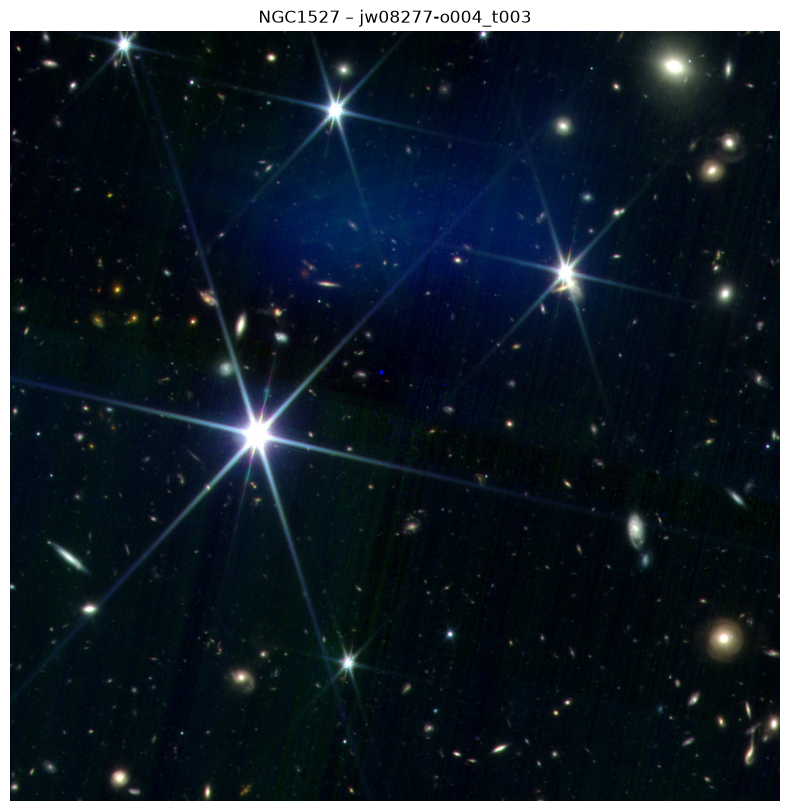

In [8]:
img = Image.open(ROOT / "output" / "runs" / f"{name}_A_chromatic_web.jpg")
plt.figure(figsize=(10, 10)); plt.imshow(img); plt.axis("off"); plt.title(f"{cand['target']} – {cand['prefix']}")

print(f"target:      {cand['target']}  ({cand['classification']})")
print(f"programme:   {cand['program']}   {cand['title']}")
print(f"position:    RA {cand['ra']:.5f}  Dec {cand['dec']:.5f}")
print(f"bands:       {sorted(cand['bands'])}")
print(f"star offsets:{result['star_offsets_px']}")
print(f"sky boxes:   {len(result['stretch']['sky_boxes']['yx'])}")
print(f"crop:        {result['export']['size_arcmin'][0]:.2f}′ x {result['export']['size_arcmin'][1]:.2f}′")
print(f"runtime:     {result['runtime_s']} s")

## Fazit

- Der Entdecker-Modus funktioniert von der Suche bis zum Bild ohne Handarbeit. Das erste fremde Feld hat sofort zwei Schwächen gezeigt, die an den Planetarischen Nebeln nicht aufgefallen waren:
  1. Ohne helles zentrales Objekt liegt der Helligkeitsschwerpunkt außerhalb der nutzbaren Fläche, also `center = "auto"` mit Rückfall auf die innerste Stelle.
  2. Bunte Einzelpixel waren weiß gefüllte defekte Pixel. Die Lücken werden jetzt nach lokalem Kontrast eingestuft (siehe Notebook 10).
- Standardwerte liefern eine brauchbare Vorschau, kein fertiges Bild. Favoriten werden von Hand in der TOML-Datei verfeinert.
- Ein Galaxienfeld braucht andere Prüfungen als ein Nebel: Streulicht, Detektorübergänge und einzelne Pixel fallen stärker auf.